# UK House Prices since 1953: Cycles, Crashes and Recoveries

**Question:** How have UK house prices moved over seven decades, how deep were the downturns, and how long did it take prices to get back to their previous peak?

**Data:** Nationwide House Price Index, UK average house price, quarterly from Q1 1953 to Q2 2025 (290 quarters), published as open data (ODC-PDDL) by the [datasets/house-prices-uk](https://github.com/datasets/house-prices-uk) project. Columns cover all properties, new properties, and (until 2015) modern and older properties.

**Tools:** Python (pandas, matplotlib).

**Important:** all prices are **nominal** (not adjusted for inflation), and Nationwide's method changed several times (simple averages until 1959, floor-area weighting to 1982, regression-based mix adjustment from 1983). Long-run comparisons should be read with that in mind.

In [1]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
})
BLUE, ORANGE, RED, GREY = "#2a78d6", "#eb6834", "#e34948", "#b8b7b2"
os.makedirs("images", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)

DATA_PATH = "data/nationwide_uk_house_prices.csv"
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/datasets/house-prices-uk/main/data/data.csv", DATA_PATH)
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])
print(raw.shape, raw["Date"].min().date(), "to", raw["Date"].max().date())
raw.tail()

(290, 9) 1953-02-01 to 2025-05-01


,Date,Price (All),Change (All),Price (New),Change (New),Price (Modern),Change (Modern),Price (Older),Change (Older)
285,2024-05-01,"265,012.0",1.2,"298,236.0",2.5,NaN,NaN,NaN,NaN
286,2024-08-01,"266,640.0",2.5,"299,191.0",-0.6,NaN,NaN,NaN,NaN
287,2024-11-01,"268,518.0",3.6,"307,673.0",4.0,NaN,NaN,NaN,NaN
288,2025-02-01,"270,867.0",3.9,"309,918.0",2.9,NaN,NaN,NaN,NaN
289,2025-05-01,"272,751.0",2.9,"313,238.0",5.0,NaN,NaN,NaN,NaN


## 1. Validate the data

In [2]:
hp = raw.set_index("Date")
price = hp["Price (All)"]

# The 'Change' columns should be the year-on-year % change of each quarterly price.
recalc = (price / price.shift(4) - 1) * 100
gap = (hp["Change (All)"] - recalc.round(1)).abs()
checks = pd.Series({
    "quarters": len(hp),
    "gaps between quarters > 92 days": int((hp.index.to_series().diff().dt.days > 92).sum()),
    "max |given YoY - recalculated YoY| (pp)": round(gap.max(), 2),
    "zero prices in Modern/Older columns": int(((hp["Price (Modern)"] == 0) | (hp["Price (Older)"] == 0)).sum()),
    "Modern/Older series end": str(hp["Price (Older)"].last_valid_index().date()),
})
checks

quarters                                          290
gaps between quarters > 92 days                     0
max |given YoY - recalculated YoY| (pp)           0.1
zero prices in Modern/Older columns                 1
Modern/Older series end                    2015-08-01
dtype: object

The published annual change matches a recalculation from the prices to within 0.1 percentage points, so it is safe to use. The *Modern* and *Older* series contain zero placeholders and stop in 2015, so the rest of the analysis uses **All** and **New** only.

In [3]:
hp = hp[["Price (All)", "Price (New)"]].rename(columns={"Price (All)": "all", "Price (New)": "new"})
hp["yoy"] = (hp["all"] / hp["all"].shift(4) - 1) * 100
hp["year"] = hp.index.year
hp.describe()

,all,new,yoy,year
count,290.0,290.0,286.0,290.0
mean,"79,179.5","87,164.9",7.5,"1,988.8"
std,"84,160.4","90,469.1",8.8,21.0
min,"1,853.0","2,107.0",-16.5,"1,953.0"
25%,"4,782.8","5,410.0",2.3,"1,971.0"
50%,"50,990.0","60,694.5",6.7,"1,989.0"
75%,"161,666.8","166,949.2",10.5,"2,007.0"
max,"273,135.0","313,238.0",42.4,"2,025.0"


## 2. Downturns: how far prices fell and how long recovery took

A downturn starts when the price drops more than 5% below its previous peak. It ends when the price first gets back to that peak.

In [4]:
episodes, peak_val, peak_date, in_dd = [], price.iloc[0], price.index[0], False
for date, p in price.items():
    if p >= peak_val:
        if in_dd:
            episodes[-1]["recovered"] = date
            in_dd = False
        peak_val, peak_date = p, date
    elif p / peak_val - 1 < -0.05 and not in_dd:
        in_dd = True
        episodes.append({"peak": peak_date, "peak_price": peak_val, "recovered": pd.NaT})

rows = []
for e in episodes:
    window = price[e["peak"]: e["recovered"] if pd.notna(e["recovered"]) else price.index[-1]]
    trough_date = window.idxmin()
    rows.append({
        "peak": f"{e['peak'].year} Q{e['peak'].quarter}",
        "trough": f"{trough_date.year} Q{trough_date.quarter}",
        "fall_pct": round((window.min() / e["peak_price"] - 1) * 100, 1),
        "quarters_peak_to_trough": len(price[e["peak"]:trough_date]) - 1,
        "recovered": f"{e['recovered'].year} Q{e['recovered'].quarter}" if pd.notna(e["recovered"]) else "not yet",
        "years_to_recover": round((len(price[e["peak"]:e["recovered"]]) - 1) / 4, 1) if pd.notna(e["recovered"]) else None,
    })
downturns = pd.DataFrame(rows)
downturns

,peak,trough,fall_pct,quarters_peak_to_trough,recovered,years_to_recover
0,1989 Q3,1993 Q1,-20.2,14,1998 Q1,8.5
1,2007 Q3,2009 Q1,-18.7,6,2014 Q2,6.8
2,2022 Q3,2023 Q1,-5.5,2,not yet,NaN


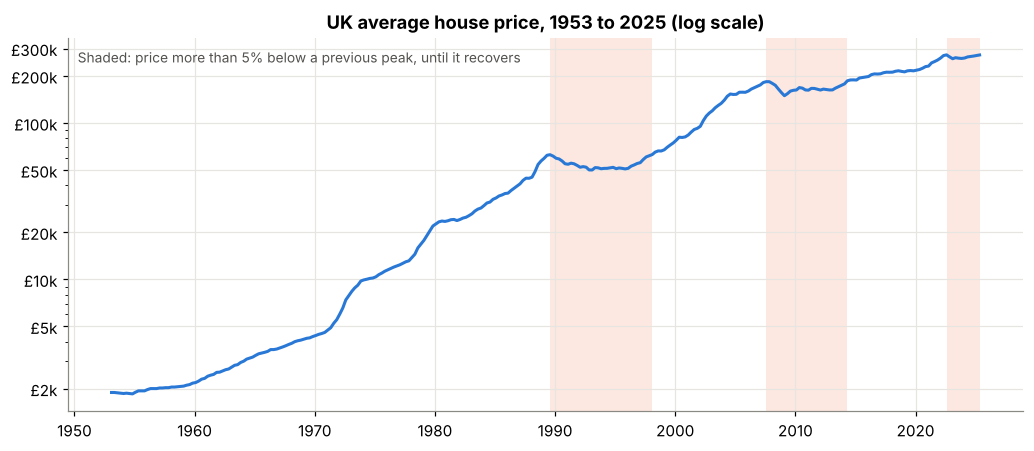

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(price.index, price.values, color=BLUE, lw=2)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k" if v >= 1000 else f"£{v:,.0f}"))
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_yticks([2000, 5000, 10000, 20000, 50000, 100000, 200000, 300000])
for e in episodes:
    end = e["recovered"] if pd.notna(e["recovered"]) else price.index[-1]
    ax.axvspan(e["peak"], end, color=ORANGE, alpha=0.15, lw=0)
ax.set_title("UK average house price, 1953 to 2025 (log scale)")
ax.text(0.01, 0.97, "Shaded: price more than 5% below a previous peak, until it recovers", transform=ax.transAxes, va="top", fontsize=9, color="#52514e")
fig.tight_layout(); fig.savefig("images/long_run_price.png"); plt.show()

## 3. Year-on-year change

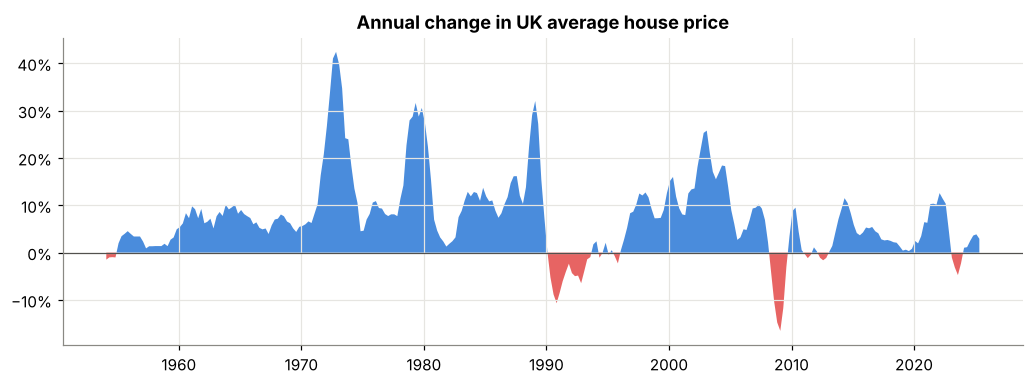

{'median_yoy_pct': np.float64(6.7),
 'share_quarters_falling_pct': np.float64(13.6),
 'max_yoy': {'pct': np.float64(42.4), 'quarter': '1972 Q4'},
 'min_yoy': {'pct': np.float64(-16.5), 'quarter': '2009 Q1'}}

In [6]:
y = hp["yoy"].dropna()
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.fill_between(y.index, y.values, 0, where=y.values >= 0, color=BLUE, alpha=0.85, lw=0, interpolate=True)
ax.fill_between(y.index, y.values, 0, where=y.values < 0, color=RED, alpha=0.85, lw=0, interpolate=True)
ax.axhline(0, color="#52514e", lw=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Annual change in UK average house price")
fig.tight_layout(); fig.savefig("images/yoy_change.png"); plt.show()

yoy_stats = {
    "median_yoy_pct": round(y.median(), 1),
    "share_quarters_falling_pct": round(100 * (y < 0).mean(), 1),
    "max_yoy": {"pct": round(y.max(), 1), "quarter": f"{y.idxmax().year} Q{y.idxmax().quarter}"},
    "min_yoy": {"pct": round(y.min(), 1), "quarter": f"{y.idxmin().year} Q{y.idxmin().quarter}"},
}
yoy_stats

## 4. Growth by decade

Compound annual growth rate (CAGR) from the first quarter of each decade to the first quarter of the next. The 1950s start in 1953 and the 2020s run to Q2 2025.

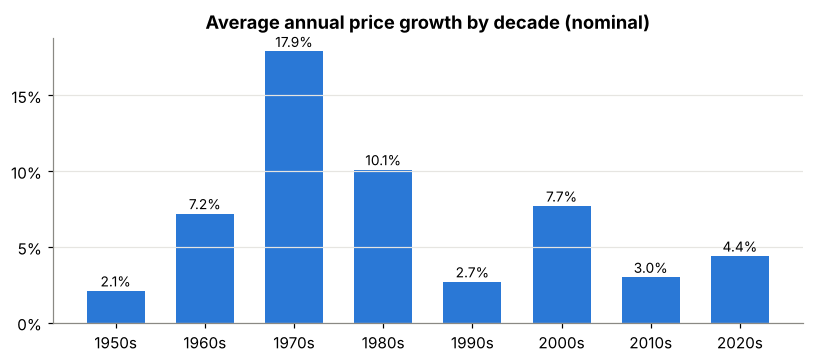

,decade,start_price,end_price,cagr_pct
0,1950s,"1,891.0","2,189.0",2.1
1,1960s,"2,189.0","4,378.0",7.2
2,1970s,"4,378.0","22,677.0",17.9
3,1980s,"22,677.0","59,587.0",10.1
4,1990s,"59,587.0","77,698.0",2.7
5,2000s,"77,698.0","162,887.0",7.7
6,2010s,"162,887.0","217,911.0",3.0
7,2020s,"217,911.0","272,751.0",4.4


In [7]:
def cagr(a, b, years):
    return (b / a) ** (1 / years) - 1

decades = []
for start in range(1950, 2030, 10):
    seg = price[(price.index.year >= start) & (price.index.year < start + 10)]
    nxt = price[price.index.year >= start + 10]
    end_val, end_date = (nxt.iloc[0], nxt.index[0]) if len(nxt) else (seg.iloc[-1], seg.index[-1])
    years = (end_date - seg.index[0]).days / 365.25
    decades.append({"decade": f"{start}s", "start_price": seg.iloc[0], "end_price": end_val,
                    "cagr_pct": round(100 * cagr(seg.iloc[0], end_val, years), 1)})
decades = pd.DataFrame(decades)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(decades["decade"], decades["cagr_pct"], color=BLUE, width=0.65)
for i, v in enumerate(decades["cagr_pct"]):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
ax.yaxis.set_major_locator(mtick.MultipleLocator(5)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="x", visible=False)
ax.set_title("Average annual price growth by decade (nominal)")
fig.tight_layout(); fig.savefig("images/growth_by_decade.png"); plt.show()
decades

## 5. The premium for new-build homes

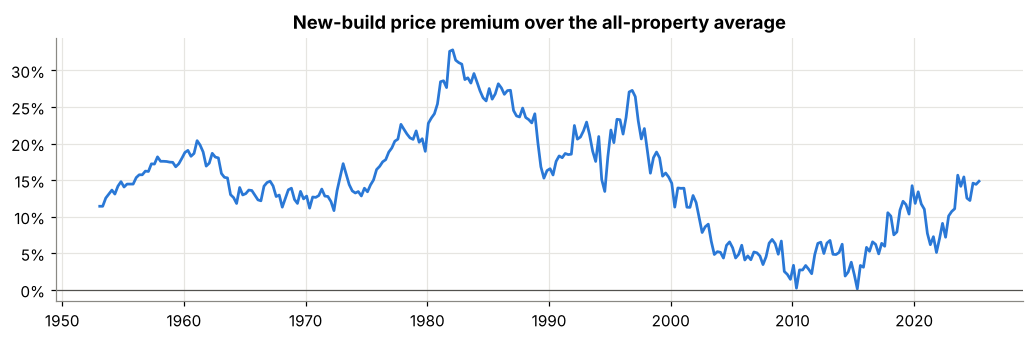

Date
1950   15.5
1960   14.9
1970   16.2
1980   26.0
1990   19.8
2000    7.1
2010    5.7
2020   11.1
dtype: float64

In [8]:
premium = (hp["new"] / hp["all"] - 1) * 100
fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.plot(premium.index, premium.values, color=BLUE, lw=1.8)
ax.axhline(0, color="#52514e", lw=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("New-build price premium over the all-property average")
fig.tight_layout(); fig.savefig("images/new_build_premium.png"); plt.show()
premium_by_decade = premium.groupby((premium.index.year // 10) * 10).mean().round(1)
premium_by_decade

## Findings

1. **The average UK home cost £1,891 in early 1953 and £272,751 in Q2 2025**, 144 times as much, or 7.1% a year compounded. Most of that is general inflation: these are nominal prices.
2. **Prices rose year on year in 86% of quarters.** The median annual change was +6.7%. The fastest was +42.4% (1972 Q4) and the steepest fall was -16.5% (2009 Q1).
3. **There have been three downturns of more than 5%:**

   | Peak | Trough | Fall | Back to previous peak |
   |---|---|---|---|
   | 1989 Q3 | 1993 Q1 | -20.2% | 1998 Q1 (8.5 years) |
   | 2007 Q3 | 2009 Q1 | -18.7% | 2014 Q2 (6.8 years) |
   | 2022 Q3 | 2023 Q1 | -5.5% | Not yet by Q2 2025 |

   The 2008 crash was nearly as deep as the early-1990s one but happened more than twice as fast: 6 quarters from peak to trough against 14.
4. **Growth has slowed decade by decade since the 1970s** (17.9% a year, in a period of very high inflation). The 2010s averaged 3.0% a year.
5. **The 2022 peak has not been regained.** In Q2 2025 the average price was still 0.1% below its 2022 Q3 level, so anyone who bought at the peak has lost value in real terms.
6. **New builds' premium has swung widely.** It averaged 26% over all homes in the 1980s, fell to about 6% in the 2010s, and was 14.8% in Q2 2025.

**Limitations.** Nominal prices only: a fair long-run comparison needs deflating by CPI, which is the next step. Nationwide's method changed in 1960, 1974 and 1983, and the index covers homes bought with Nationwide mortgages, not cash buyers. The series ends in Q2 2025.

In [9]:
latest = price.index[-1]
summary = {
    "first": {"quarter": f"{price.index[0].year} Q{price.index[0].quarter}", "price": float(price.iloc[0])},
    "latest": {"quarter": f"{latest.year} Q{latest.quarter}", "price": float(price.iloc[-1])},
    "multiple": round(float(price.iloc[-1] / price.iloc[0]), 1),
    "overall_cagr_pct": round(100 * cagr(price.iloc[0], price.iloc[-1], (latest - price.index[0]).days / 365.25), 1),
    "checks": {k: (v if isinstance(v, str) else float(v)) for k, v in checks.items()},
    "downturns": downturns.to_dict(orient="records"),
    "yoy_stats": yoy_stats,
    "decades": decades[["decade", "cagr_pct"]].to_dict(orient="records"),
    "premium_latest_pct": round(float(premium.iloc[-1]), 1),
    "premium_by_decade": {str(k): float(v) for k, v in premium_by_decade.items()},
    "series": [{"q": f"{d.year} Q{d.quarter}", "price": float(p)} for d, p in price.items()],
    "yoy": [{"q": f"{d.year} Q{d.quarter}", "pct": round(float(v), 1)} for d, v in y.items()],
    "episodes": [{"start": f"{e['peak'].year} Q{e['peak'].quarter}",
                  "end": (f"{e['recovered'].year} Q{e['recovered'].quarter}" if pd.notna(e["recovered"]) else None)} for e in episodes],
}
json.dump(summary, open("results/summary.json", "w"), indent=1, default=str)
print("saved results/summary.json")

saved results/summary.json
